# Notebook 2: Perbandingan Arsitektur Model

Muhammad Athallah Adriansyah · 2702831114 · COMP8044041 Deep Learning

Notebook ini membandingkan sebelas model untuk analisis sentimen berbasis aspek pada dataset HoASA, mulai dari model klasik TF-IDF sampai Transformer berukuran besar. Model inti disusun sebagai rantai. Setiap model menambahkan satu gagasan pada model sebelumnya, dan gagasan tersebut dipilih berdasarkan temuan eksplorasi data di notebook 1. Dengan susunan ini, selisih performa dua model yang berurutan dapat dibaca sebagai sumbangan gagasan yang ditambahkan.

| Kode | Model | Gagasan yang ditambahkan | Dasar dari notebook 1 |
|---|---|---|---|
| Ref | TF-IDF + Logistic Regression | n-gram kata 1–2 dan karakter 2–5, tanpa deep learning | 89% opini berjarak ≤ 5 kata dari aspeknya (bagian 5.9); pembanding untuk menilai perlu tidaknya deep learning |
| A | BiLSTM | membaca urutan kata dari dua arah dengan embedding FastText | polaritas bergantung pada negasi dan kontras (bagian 5.8); kosakata berekor panjang (bagian 5.7) |
| B | BiLSTM + Attention | semua token ikut membentuk representasi ulasan | 59% ulasan membahas ≥ 2 aspek (bagian 5.4), sehingga satu state terakhir harus merangkum terlalu banyak |
| C | TextCNN | detektor frasa pendek (filter 2–5 kata) dengan max pooling | 64% pasangan aspek–opini berjarak ≤ 2 kata (bagian 5.9) |
| D | IndoBERT-base | Transformer pretrained berbahasa Indonesia | data latih 2.260 ulasan, OOV 5,7% (bagian 5.7), aspek implisit (bagian 4.5); fertility tokenizer terendah (bagian 7.7) |
| E | XLM-R-base | Transformer multibahasa (100 bahasa) | 11,5% ulasan bercampur kode bahasa Inggris (bagian 4.6) |
| F | IndoBERT-large | model D dengan 24 lapis | pengaruh kapasitas pada model monolingual |
| G | XLM-R-large | model E dengan 24 lapis | pengaruh kapasitas pada model multibahasa; terbaik di paper IndoNLU |

LSTM satu arah, mBERT, dan IndoBERTweet ikut dilatih sebagai pembanding di luar rantai. Semua angka dibaca dari hasil pelatihan yang tersimpan di `outputs/`, sehingga notebook ini tidak melatih ulang model.

## 1. Protokol Eksperimen dan Dasar Hiperparameter

Seluruh model memakai split resmi IndoNLU dan data latih hasil pembersihan di notebook 1 (2.260 ulasan). Epoch terbaik dipilih dengan F1 valid, lalu F1 test pada epoch tersebut dilaporkan. Test tidak pernah dipakai untuk memilih model ataupun hiperparameter.

Metrik utama adalah F1 resmi IndoNLU, yaitu macro-F1 atas seluruh sel ulasan × aspek. Sebagai pelengkap, dilaporkan F1 pasangan aspek–polaritas dan exact match (kesepuluh aspek satu ulasan benar). Model neural dilatih dengan tiga seed dan dilaporkan sebagai rata-rata ± simpangan baku; TF-IDF + LR deterministik sehingga cukup dijalankan sekali.

Semua model memakai satu encoder bersama dengan keluaran 10 aspek × 4 kelas dan dilatih dengan cross-entropy. Saat prediksi, probabilitas `neg_pos` dijumlahkan ke `neg` sehingga keluaran akhir selalu tiga kelas (bagian 3.1 dan 8).

Tidak dilakukan pencarian hiperparameter per model. Setiap keluarga model memakai satu resep dengan dasar sebagai berikut.

| Hiperparameter | Nilai | Dasar |
|---|---|---|
| Input teks | model kata `text_norm`, transformer `text_clean` | stemming dan lemmatisasi menurunkan F1 IndoBERT, normalisasi sedikit membantu model kata (notebook 1 bagian 7.8) |
| Panjang maksimum | 128 subword (transformer), 128 kata (model kata) | persentil ke-99 panjang subword 84 (IndoBERT) dan 98 (XLM-R); hanya 0,2–0,3% ulasan terpotong (notebook 1 bagian 7.7). Ulasan terpanjang 139 token setelah normalisasi |
| n-gram TF-IDF | kata 1–2, karakter 2–5, C = 10, bobot kelas seimbang | opini lokal; n-gram karakter menyerap imbuhan dan salah ketik; dipilih dengan validasi silang di notebook 1 |
| Embedding model kata | FastText `cc.id.300`, ikut dilatih dengan lr 1e-4 | kata OOV tetap memperoleh vektor dari n-gram karakter (Grave dkk., 2018); lr kecil menjaga vektor pretrained |
| BiLSTM | 2 lapis, 128 unit per arah, dropout 0,3 | kapasitas kecil (sekitar 2 juta parameter) sesuai ukuran data |
| Filter TextCNN | lebar 2, 3, 4, 5 × 128 filter, dropout 0,5 | Kim (2014); lebar 2 ditambahkan karena jarak aspek–opini tersering adalah 2 kata |
| Optimizer model kata | Adam, lr 1e-3, batch 32, maksimum 100 epoch, patience 10 | nilai baku Adam; patience longgar karena model kata naik perlahan (bagian 6) |
| Optimizer transformer | AdamW, lr 3e-5, weight decay 0,01, warmup 10% lalu linear, batch 32 | rekomendasi Devlin dkk. (2019) untuk fine-tuning BERT |
| Learning rate XLM-R | base 2e-5, large 1e-5 | XLM-R tidak stabil pada learning rate besar (Mosbach dkk., 2021) |
| Epoch transformer | maksimum 20, patience 5 | pada data kecil, fine-tuning lebih lama lebih stabil (Mosbach dkk., 2021) |
| Gradient clipping | 1,0 | mencegah ledakan gradien; diterapkan ke semua model agar seragam |
| Pembobotan kelas | tidak ada | mengikuti formulasi IndoNLU agar sebanding dengan paper |
| Seed | 42, 1337, 2024 | test hanya 286 ulasan; tiga seed mengukur kestabilan hasil |

## 2. Persiapan

Sel berikut memuat pustaka, fungsi bantu, dan hasil seluruh run yang tersimpan.

In [1]:
import inspect
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from hoasa.data import load_processed, to_ids
from hoasa.metrics import metrics
from hoasa.train import slug


def show_code(*objs):
    """Tampilkan kode sumber asli dari src/ (kode yang benar-benar dipakai saat pelatihan, bukan salinan)."""
    display(Markdown("```python\n" + "\n\n\n".join(inspect.getsource(o).rstrip() for o in objs) + "\n```"))


FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220)

SURFACE, INK, INK_2, GRID, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#b5b3ad"
FAMILY_COLOR = {"transformer": "#2a78d6", "kata": "#eb6834", "klasik": "#1baf7a"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False,
})

In [2]:
# urutan = tangga model di atas; run mitigasi (notebook 3) tidak ikut di sini
MODELS = ["TF-IDF + LR", "LSTM", "BiLSTM", "BiLSTM + Attention", "TextCNN", "mBERT-base", "XLM-R-base",
          "IndoBERTweet-base", "IndoBERT-base", "IndoBERT-large", "XLM-R-large"]
FAMILY = {m: "klasik" if m.startswith("TF-IDF") else "kata" if i < 5 else "transformer" for i, m in enumerate(MODELS)}


def load_results(path):
    rows = []
    for line in open(path):
        r = json.loads(line)
        rows.append({"model": r["name"], "seed": r["seed"], "best_epoch": r["best_epoch"], "params": r["params"],
                     "menit": r["minutes"], "history": r["history"],
                     **{f"{s}_{k}": r[s][k] for s in ["valid", "test"] for k in ["f1_indonlu", "f1_pair", "exact"]}})
    return pd.DataFrame(rows)


runs = load_results(ROOT / "outputs" / "results.jsonl")
runs = runs[runs.model.isin(MODELS)].reset_index(drop=True)
Y = {s: to_ids(load_processed(s)) for s in ["valid", "test"]}
print(f"{len(runs)} run dari {runs.model.nunique()} model")
runs.groupby("model", sort=False).seed.apply(list).to_frame("seed")

31 run dari 11 model


,seed
model,
TF-IDF + LR,[0]
LSTM,"[42, 1337, 2024]"
BiLSTM,"[42, 1337, 2024]"
BiLSTM + Attention,"[42, 1337, 2024]"
TextCNN,"[42, 1337, 2024]"
IndoBERT-base,"[42, 1337, 2024]"
IndoBERTweet-base,"[42, 1337, 2024]"
mBERT-base,"[42, 1337, 2024]"
XLM-R-base,"[42, 1337, 2024]"


## 3. Arsitektur dan Kode Inti

Kode pada bagian ini adalah kode asli dari `src/hoasa/` yang dipakai saat pelatihan, ditampilkan dengan fungsi `show_code`. Setiap jenis model juga dijalankan pada satu ulasan test untuk memperlihatkan bentuk tensor. Demo memakai bobot yang belum dilatih, sehingga prediksinya belum bermakna; prediksi model terlatih ada di notebook 3 bagian 6.

Skema 1 memperlihatkan alur yang sama untuk semua model. Perbedaan antarmodel hanya terletak pada encoder.

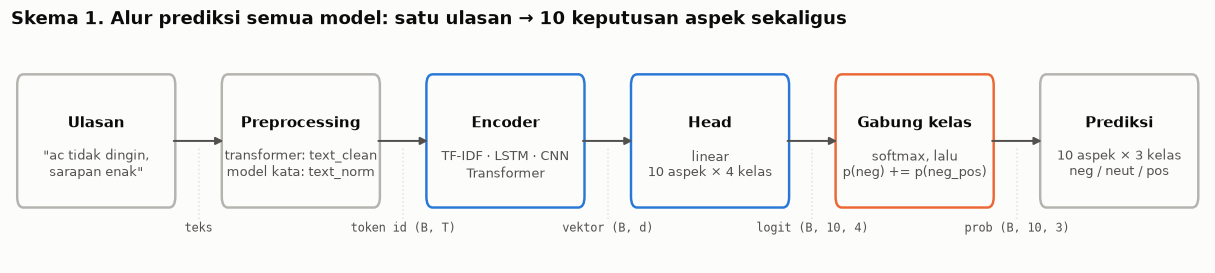

In [3]:
from matplotlib.patches import FancyBboxPatch

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"


def box(ax, x, y, w, h, title, sub="", color=MUTED):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=SURFACE, ec=color, lw=1.6))
    ax.text(x, y + (0.13 if sub else 0), title, ha="center", va="center", fontsize=9.6, fontweight="bold", color=INK)
    if sub:
        ax.text(x, y - 0.17, sub, ha="center", va="center", fontsize=8.3, color=INK_2, linespacing=1.3)


def arrow(ax, x0, y0, x1, y1):
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="-|>", color=INK_2, lw=1.3, shrinkA=0, shrinkB=0))


fig, ax = plt.subplots(figsize=(14, 2.7))
ax.set_xlim(0, 15.4)
ax.set_ylim(-0.1, 1.6)
ax.axis("off")
B = [("Ulasan", "\"ac tidak dingin,\nsarapan enak\"", MUTED), ("Preprocessing", "transformer: text_clean\nmodel kata: text_norm", MUTED),
     ("Encoder", "TF-IDF · LSTM · CNN\nTransformer", BLUE), ("Head", "linear\n10 aspek × 4 kelas", BLUE),
     ("Gabung kelas", "softmax, lalu\np(neg) += p(neg_pos)", ORANGE), ("Prediksi", "10 aspek × 3 kelas\nneg / neut / pos", MUTED)]
xs, w = [1.1 + i * 2.64 for i in range(6)], 2.0
for x, (t, sub, c) in zip(xs, B):
    box(ax, x, 0.8, w, 0.95, t, sub, c)
for x0, x1, lab in zip(xs, xs[1:], ["teks", "token id (B, T)", "vektor (B, d)", "logit (B, 10, 4)", "prob (B, 10, 3)"]):
    arrow(ax, x0 + w / 2, 0.8, x1 - w / 2, 0.8)
    ax.text((x0 + x1) / 2, 0.2, lab, ha="center", va="top", fontsize=8, color=INK_2, family="monospace")
    ax.plot([(x0 + x1) / 2] * 2, [0.22, 0.76], color=GRID, lw=1, ls=":")
ax.set_title("Skema 1. Alur prediksi semua model: satu ulasan → 10 keputusan aspek sekaligus")
fig.savefig(FIG_DIR / "skema_1_alur_model.png")
plt.show()

### 3.1 Label: dilatih dengan empat kelas, diprediksi dalam tiga kelas

Fungsi `load_data` memuat label latih empat kelas dari kolom `<aspek>_orig`, sedangkan data valid dan test memakai label evaluasi tiga kelas. Fungsi `fold` menjumlahkan probabilitas `neg_pos` ke `neg` setelah softmax.

In [4]:
import torch

from hoasa.data import CLASSES, load_processed
from hoasa.train import fit, fold, load_data, run_transformer

show_code(load_data, fold)

```python
def load_data():
    data = {s: load_processed(s) for s in ["train", *EVAL_SPLITS]}
    Y = {s: to_ids(d) for s, d in data.items()}
    Y["train"] = to_ids(data["train"][[f"{a}_orig" for a in ASPECTS]].set_axis(ASPECTS, axis=1))   # 4 kelas
    return data, Y


def fold(p):
    """Probabilitas 4 kelas -> 3 kelas: neg_pos (aspek dibahas negatif dan positif) dihitung sebagai neg."""
    p = np.array(p, dtype=np.float32)
    p[..., 0] += p[..., 3]
    return p[..., :3]
```

In [5]:
p = np.array([0.30, 0.10, 0.35, 0.25])   # probabilitas satu aspek: neg, neut, pos, neg_pos
show = lambda q: "  ".join(f"{c} {v:.2f}" for c, v in zip(CLASSES, q))
print("4 kelas:", show(p), " -> argmax", CLASSES[p.argmax()])
print("3 kelas:", show(fold(p)), " -> argmax", CLASSES[fold(p).argmax()])

4 kelas: neg 0.30  neut 0.10  pos 0.35  neg_pos 0.25  -> argmax pos
3 kelas: neg 0.55  neut 0.10  pos 0.35  -> argmax neg


Contoh di atas memperlihatkan alasan penggabungan dilakukan setelah softmax. Probabilitas kritik (`neg` 0,30 dan `neg_pos` 0,25) lebih besar daripada `pos`, tetapi argmax empat kelas memilih `pos` karena kritik terbagi ke dua kelas. Setelah digabung, `neg` memperoleh 0,55 dan menjadi prediksi.

### 3.2 Model berbasis kata

Keempat model kata memakai embedding FastText `cc.id.300` dan `Head` yang sama, yaitu satu lapis linear yang menghasilkan 10 × 4 logit. Perbedaannya terletak pada cara urutan kata dirangkum menjadi satu vektor.

| Model | Cara merangkum ulasan |
|---|---|
| LSTM | state tersembunyi pada token terakhir |
| BiLSTM | state akhir arah maju dan state awal arah mundur |
| BiLSTM + Attention | rata-rata berbobot attention dan max pooling atas semua token |
| TextCNN | filter n-gram 2–5 dan max-over-time pooling |

In [6]:
from hoasa.models import LSTM, BiLSTM, BiLSTMAttn, Head, TextCNN

show_code(Head, LSTM, BiLSTM)

```python
class Head(nn.Module):
    """Satu lapis linear bersama untuk 10 aspek x 3 kelas."""

    def __init__(self, dim, dropout):
        super().__init__()
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(dim, len(ASPECTS) * N_CLS)

    def forward(self, h):
        return self.out(self.drop(h)).view(-1, len(ASPECTS), N_CLS)


class LSTM(WordModel):
    """LSTM searah 2 lapis; representasi = state tersembunyi pada token terakhir (bukan padding)."""

    def __init__(self, emb, hidden=256):
        super().__init__(emb)
        self.rnn = nn.LSTM(emb.shape[1], hidden, num_layers=2, batch_first=True, dropout=0.3)
        self.head = Head(hidden, 0.3)

    def forward(self, x):
        h, _ = self.rnn(self.drop(self.emb(x)))
        last = (x != 0).sum(1).clamp(min=1) - 1
        return self.head(h[torch.arange(len(x)), last])


class BiLSTM(WordModel):
    """BiLSTM 2 lapis; representasi = state akhir arah maju + state awal arah mundur."""

    def __init__(self, emb, hidden=128):
        super().__init__(emb)
        self.hidden = hidden
        self.rnn = nn.LSTM(emb.shape[1], hidden, num_layers=2, batch_first=True, bidirectional=True, dropout=0.3)
        self.head = Head(2 * hidden, 0.3)

    def forward(self, x):
        h, _ = self.rnn(self.drop(self.emb(x)))
        last = (x != 0).sum(1).clamp(min=1) - 1
        fwd = h[torch.arange(len(x)), last, :self.hidden]
        bwd = h[:, 0, self.hidden:]
        return self.head(torch.cat([fwd, bwd], -1))
```

In [7]:
show_code(BiLSTMAttn, TextCNN)

```python
class BiLSTMAttn(WordModel):
    """BiLSTM 2 lapis + attention pooling dan max pooling atas semua token (Zhou et al., 2016)."""

    def __init__(self, emb, hidden=128):
        super().__init__(emb)
        self.rnn = nn.LSTM(emb.shape[1], hidden, num_layers=2, batch_first=True, bidirectional=True, dropout=0.3)
        self.att = nn.Linear(2 * hidden, 1)
        self.head = Head(4 * hidden, 0.3)

    def forward(self, x):
        mask = x != 0
        h, _ = self.rnn(self.drop(self.emb(x)))
        a = self.att(h).squeeze(-1).masked_fill(~mask, -1e9).softmax(-1)
        att = (a.unsqueeze(-1) * h).sum(1)
        mx = h.masked_fill(~mask.unsqueeze(-1), -1e9).max(1).values
        return self.head(torch.cat([att, mx], -1))


class TextCNN(WordModel):
    """CNN teks (Kim, 2014): filter lebar 2-5, max-over-time pooling."""

    def __init__(self, emb, n_filters=128, widths=(2, 3, 4, 5)):
        super().__init__(emb)
        self.convs = nn.ModuleList(nn.Conv1d(emb.shape[1], n_filters, w, padding=w - 1) for w in widths)
        self.head = Head(n_filters * len(widths), 0.5)

    def forward(self, x):
        mask = (x != 0).unsqueeze(1)
        e = self.drop(self.emb(x)).transpose(1, 2)
        feats = []
        for conv in self.convs:
            c = torch.relu(conv(e))[..., :x.shape[1]]
            feats.append(c.masked_fill(~mask, -1e9).max(-1).values)
        return self.head(torch.cat(feats, -1))
```

In [8]:
from hoasa.preprocess import TOKEN_RE

test = load_processed("test")
DEMO = 59                                                     # ulasan test yang juga dipakai di notebook 3
words = TOKEN_RE.findall(test.text_norm[DEMO])
vocab = {w: i + 2 for i, w in enumerate(sorted(set(words)))}  # 0 = padding, 1 = kata tidak dikenal
x = torch.tensor([[vocab[w] for w in words]])                 # (batch=1, T)
emb = np.random.default_rng(0).normal(0, 0.1, (len(vocab) + 2, 300)).astype(np.float32)   # pengganti FastText 300 dimensi

print("ulasan (text_norm):", test.text_norm[DEMO])
print("input token id    :", tuple(x.shape))
torch.manual_seed(0)
for M in [LSTM, BiLSTM, BiLSTMAttn, TextCNN]:
    m = M(emb).eval()
    n = sum(p.numel() for name, p in m.named_parameters() if not name.startswith("emb"))
    print(f"{M.__name__:11s} -> logit {tuple(m(x).shape)}  | parameter di luar embedding: {n / 1e6:.2f} juta")

ulasan (text_norm): 4 hari inap tanpa snack padahal standar nya airy selalu ada snack handuk di hari 3 tidak kebagian kalau soal kebersihan tidak ada masalah cuma fasilitas nya saja yang kurang bisa dipenuhi
input token id    : (1, 32)
LSTM        -> logit (1, 10, 4)  | parameter di luar embedding: 1.11 juta
BiLSTM      -> logit (1, 10, 4)  | parameter di luar embedding: 0.85 juta
BiLSTMAttn  -> logit (1, 10, 4)  | parameter di luar embedding: 0.86 juta
TextCNN     -> logit (1, 10, 4)  | parameter di luar embedding: 0.56 juta


Keempat model mengubah ulasan sepanjang 32 token menjadi logit berukuran (1, 10, 4). Di luar embedding, jumlah parameternya hanya 0,56–1,11 juta.

### 3.3 Transformer

Pada transformer, encoder diganti dengan model pretrained dari Hugging Face, dan `Head` yang sama ditempatkan di atas vektor token pertama (`[CLS]` atau `<s>`). Demo berikut memakai IndoBERT-base pada ulasan yang sama dengan input `text_clean`.

In [9]:
from hoasa.models import TransformerCLS

show_code(TransformerCLS)

```python
class TransformerCLS(nn.Module):
    """Encoder pretrained + head linear di atas vektor token pertama ([CLS] / <s>)."""

    def __init__(self, name):
        from transformers import AutoModel
        super().__init__()
        self.enc = AutoModel.from_pretrained(name)
        self.head = Head(self.enc.config.hidden_size, 0.1)

    def forward(self, input_ids, attention_mask):
        h = self.enc(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0]
        return self.head(h)
```

In [10]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")
from huggingface_hub.utils import logging as hub_logging
from transformers import AutoTokenizer
from transformers.utils import logging as hf_logging

hub_logging.set_verbosity_error()
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
BACKBONE = "indobenchmark/indobert-base-p1"
tok = AutoTokenizer.from_pretrained(BACKBONE)
enc = tok(test.text_clean[DEMO], return_tensors="pt")
print("subword:", tok.convert_ids_to_tokens(enc["input_ids"][0]))

torch.manual_seed(0)
model = TransformerCLS(BACKBONE).eval()
with torch.no_grad():
    logit = model(enc["input_ids"], enc["attention_mask"])
prob = fold(logit.softmax(-1).numpy())
print("input_ids", tuple(enc["input_ids"].shape), "-> logit", tuple(logit.shape), "-> setelah fold", prob.shape)
print(f"parameter: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} juta (encoder pretrained + head {sum(p.numel() for p in model.head.parameters()):,})")

subword: ['[CLS]', '4', 'hari', 'inap', 'tanpa', 'snack', ',', 'padahal', 'standar', 'nya', 'air', '##y', 'selalu', 'ada', 'snack', '.', 'handuk', 'di', 'hari', '3', 'gak', 'kebagian', '.', 'kalo', 'soal', 'kebersihan', 'gak', 'ada', 'masalah', '.', 'cuma', 'fasilitas', 'nya', 'aja', 'yg', 'kurang', 'bisa', 'dipenuhi', '.', '[SEP]']


input_ids (1, 40) -> logit (1, 10, 4) -> setelah fold (1, 10, 3)
parameter: 124.5 juta (encoder pretrained + head 30,760)


Ulasan tersebut dipecah menjadi 40 subword, dan keluarannya berbentuk (1, 10, 4) seperti pada model kata. IndoBERT-base memiliki 124,5 juta parameter, sedangkan head-nya hanya 30.760 parameter.

### 3.4 Loop pelatihan

Fungsi `fit` dipakai oleh semua model neural. Pada setiap epoch, model dilatih dengan cross-entropy empat kelas, kemudian F1 valid dan test dihitung. Epoch dengan F1 valid tertinggi disimpan, dan pelatihan dihentikan apabila F1 valid tidak meningkat selama `patience` epoch. Nilai test hanya dicatat.

In [11]:
show_code(fit)

```python
def fit(name, seed, model, opt, sched, train_batches, predict, Y, epochs, patience, smooth=0.0, on_best=None):
    """train_batches(rng) -> iterasi (input, y 4 kelas); predict(split) -> probabilitas 3 kelas (n, 10, 3).

    on_best(): dipanggil setiap F1 valid membaik, mis. untuk menyalin bobot epoch terbaik.
    """
    best, history, bad, t0 = {"epoch": 0, "valid": {"f1_indonlu": -1}}, [], 0, time.time()
    rng = torch.Generator().manual_seed(seed)
    for ep in range(1, epochs + 1):
        model.train()
        losses = []
        for inp, y in train_batches(rng):
            loss = F.cross_entropy(model(*inp).float().reshape(-1, N_CLS), y.reshape(-1), label_smoothing=smooth)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            if sched:
                sched.step()
            losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            probs = {s: predict(s) for s in EVAL_SPLITS}
        m = {s: metrics(Y[s], probs[s].argmax(-1)) for s in EVAL_SPLITS}
        history.append({"epoch": ep, "loss": round(float(np.mean(losses)), 5),
                        "valid_f1": round(m["valid"]["f1_indonlu"], 5), "test_f1": round(m["test"]["f1_indonlu"], 5)})
        improved = m["valid"]["f1_indonlu"] > best["valid"]["f1_indonlu"]
        if improved:
            best, bad = {"epoch": ep, **m, "probs": probs}, 0
            if on_best:
                on_best()
        else:
            bad += 1
        print(f"[{name} s{seed}] ep {ep:2d} loss {np.mean(losses):.4f} valid f1 {m['valid']['f1_indonlu']:.4f}"
              f"{' *' if improved else ''} ({time.time() - t0:.0f}s)", flush=True)
        if bad >= patience:
            break
    return best, history, time.time() - t0
```

Fungsi `run_transformer` menyiapkan data, model, dan optimizer untuk `fit`. Teks ditokenisasi sekali di awal, dan padding yang tidak terpakai dipotong per batch. Optimizer AdamW memakai dua kelompok parameter sehingga head dapat diberi learning rate yang berbeda dari encoder. Learning rate dinaikkan bertahap selama 10% langkah pertama, lalu diturunkan secara linear, dan perhitungan memakai bf16 agar pelatihan di GPU lebih cepat. Parameter `head` memilih head `"cls"` untuk notebook ini, atau head `"aspect"` dan `"aspect_desc"` untuk pendekatan baru di notebook 3.

In [12]:
show_code(run_transformer)

```python
def run_transformer(name, seed, backbone, text="clean", lr=3e-5, epochs=20, patience=5, bs=32, max_len=128,
                    head="cls", head_lr=None, smooth=0.0, save_dir=None):
    """Fine-tuning penuh: AdamW (wd 0,01), warmup 10% + decay linear, bf16, clip 1,0, early stopping F1 valid.

    head: "cls" (linear di atas token pertama), "aspect" (attention per aspek, query acak) atau "aspect_desc"
    (attention per aspek, query diinisialisasi dari deskripsi aspek hasil `aspect_descriptions`).
    head_lr: learning rate parameter head (default sama dengan lr). smooth: label smoothing cross-entropy.
    save_dir: jika diisi, bobot epoch terbaik disimpan ke save_dir/model.pt beserta konfigurasinya (config.json).
    """
    from transformers import AutoTokenizer

    data, Y = load_data()
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(backbone)
    enc = {s: tok(d[f"text_{text}"].tolist(), max_length=max_len, truncation=True, padding=True, return_tensors="pt")
           for s, d in data.items()}
    Yt = {s: torch.tensor(y) for s, y in Y.items()}
    desc = aspect_descriptions(data["train"]) if head == "aspect_desc" else None
    if head == "cls":
        model = TransformerCLS(backbone)
    else:
        model = TransformerAspect(backbone, encode_descriptions(backbone, tok, desc) if desc else None)
    model.to(DEV)
    enc_params = list(model.enc.parameters())
    ids = {id(p) for p in enc_params}
    opt = torch.optim.AdamW([{"params": enc_params},
                             {"params": [p for p in model.parameters() if id(p) not in ids], "lr": head_lr or lr}],
                            lr=lr, weight_decay=0.01)
    steps = epochs * math.ceil(len(Y["train"]) / bs)
    warm = max(1, int(0.1 * steps))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min((s + 1) / warm, max(0.0, (steps - s) / (steps - warm))))

    def batch(split, idx):
        m = enc[split]["attention_mask"][idx]
        n = int(m.sum(1).max())                          # potong padding yang tidak terpakai di batch ini
        return enc[split]["input_ids"][idx, :n].to(DEV), m[:, :n].to(DEV)

    class BF16(nn.Module):                               # bungkus forward dengan autocast bf16
        def __init__(self, m):
            super().__init__()
            self.m = m

        def forward(self, ids, mask):
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=DEV == "cuda"):
                return self.m(ids, mask)

    wrapped = BF16(model)

    def train_batches(rng):
        for b in torch.randperm(len(Y["train"]), generator=rng).split(bs):
            yield batch("train", b), Yt["train"][b].to(DEV)

    def predict(split):
        idx = torch.arange(len(Y[split])).split(128)
        return fold(torch.cat([wrapped(*batch(split, b)).float().softmax(-1).cpu() for b in idx]))

    state = {}

    def keep_best():
        state.update({k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()})

    best, history, secs = fit(name, seed, wrapped, opt, sched, train_batches, predict, Y, epochs, patience, smooth,
                              keep_best if save_dir else None)
    cfg = {"backbone": backbone, "text": text, "lr": lr, "bs": bs, "epochs": epochs, "patience": patience,
           "max_len": max_len, "head": head, "head_lr": head_lr, "smooth": smooth, **({"desc": desc} if desc else {})}
    if save_dir:
        save_dir.mkdir(parents=True, exist_ok=True)
        torch.save(state, save_dir / "model.pt")
        (save_dir / "config.json").write_text(json.dumps({"name": name, "seed": seed, "best_epoch": best["epoch"],
                                                          **cfg}, indent=1))
    save_run(name, "transformer", seed, cfg, best, history, secs, sum(p.numel() for p in model.parameters()))
    del model, wrapped, opt
    torch.cuda.empty_cache()
```

### 3.5 Konfigurasi yang dijalankan

Tabel berikut dibaca dari konfigurasi yang disimpan bersama setiap run, sehingga sama dengan konfigurasi yang dipakai saat pelatihan.

In [13]:
CFG_COLS = ["backbone", "arch", "text", "lr", "emb_lr", "bs", "epochs", "patience", "max_len", "C"]
cfg = {}
for line in open(ROOT / "outputs" / "results.jsonl"):
    r = json.loads(line)
    if r["name"] in MODELS and r["name"] not in cfg:
        cfg[r["name"]] = {k: r["cfg"].get(k) for k in CFG_COLS}
pd.DataFrame(cfg).T.loc[MODELS].dropna(axis=1, how="all").fillna("–")

,backbone,arch,text,lr,emb_lr,bs,epochs,patience,max_len,C
TF-IDF + LR,–,–,norm,–,–,–,–,–,–,10.0
LSTM,–,lstm,norm,0.001,0.0001,32,100,10,–,–
BiLSTM,–,bilstm,norm,0.001,0.0001,32,100,10,–,–
BiLSTM + Attention,–,bilstm_attn,norm,0.001,0.0001,32,100,10,–,–
TextCNN,–,cnn,norm,0.001,0.0001,32,100,10,–,–
mBERT-base,google-bert/bert-base-multilingual-uncased,–,clean,0.00003,–,32,20,5,128,–
XLM-R-base,FacebookAI/xlm-roberta-base,–,clean,0.00002,–,32,20,5,128,–
IndoBERTweet-base,indolem/indobertweet-base-uncased,–,clean,0.00003,–,32,20,5,128,–
IndoBERT-base,indobenchmark/indobert-base-p1,–,clean,0.00003,–,32,20,5,128,–
IndoBERT-large,indobenchmark/indobert-large-p2,–,clean,0.00003,–,32,20,5,128,–


## 4. Hasil Utama dan Uji Signifikansi

Tabel berikut berisi rata-rata tiga seed beserta simpangan bakunya, diurutkan menurut F1 test. Kolom epoch menunjukkan rata-rata epoch terbaik menurut valid.

In [14]:
def summarize(df):
    g = df.groupby("model", sort=False)
    out = pd.DataFrame({
        "keluarga": [FAMILY.get(m, "") for m in g.groups],
        "F1 valid": g.valid_f1_indonlu.mean(), "F1 test": g.test_f1_indonlu.mean(), "± sd": g.test_f1_indonlu.std(),
        "F1 pasangan": g.test_f1_pair.mean(), "exact match": g.test_exact.mean(),
        "epoch": g.best_epoch.mean(), "parameter (juta)": g.params.first() / 1e6, "menit/run": g.menit.mean(),
    }, index=list(g.groups))
    return out


table = summarize(runs).sort_values("F1 test", ascending=False)
display(table.style.format({c: "{:.4f}" for c in ["F1 valid", "F1 test", "± sd", "F1 pasangan", "exact match"]}
                           | {"epoch": "{:.1f}", "parameter (juta)": "{:.1f}", "menit/run": "{:.1f}"}, na_rep="–"))

,keluarga,F1 valid,F1 test,± sd,F1 pasangan,exact match,epoch,parameter (juta),menit/run
XLM-R-large,transformer,0.9279,0.9423,0.0047,0.9247,0.7879,18.7,559.9,10.3
IndoBERT-large,transformer,0.9220,0.9341,0.0049,0.9138,0.7611,12.0,335.2,6.4
IndoBERT-base,transformer,0.9087,0.9280,0.0064,0.9068,0.7517,13.0,124.5,2.6
IndoBERTweet-base,transformer,0.8972,0.9146,0.0104,0.8921,0.7238,14.7,110.6,2.8
XLM-R-base,transformer,0.8914,0.9127,0.0038,0.8909,0.7413,17.3,278.1,4.6
TextCNN,kata,0.8792,0.8918,0.0018,0.8688,0.6760,36.3,1.8,0.3
mBERT-base,transformer,0.8746,0.8898,0.0055,0.8636,0.6818,15.7,167.4,3.2
TF-IDF + LR,klasik,0.8443,0.8779,–,0.8466,0.6189,0.0,0.6,0.0
BiLSTM + Attention,kata,0.8550,0.8599,0.0102,0.8314,0.6212,37.7,2.1,0.3
BiLSTM,kata,0.8220,0.8420,0.0091,0.8186,0.6096,52.7,2.1,0.5


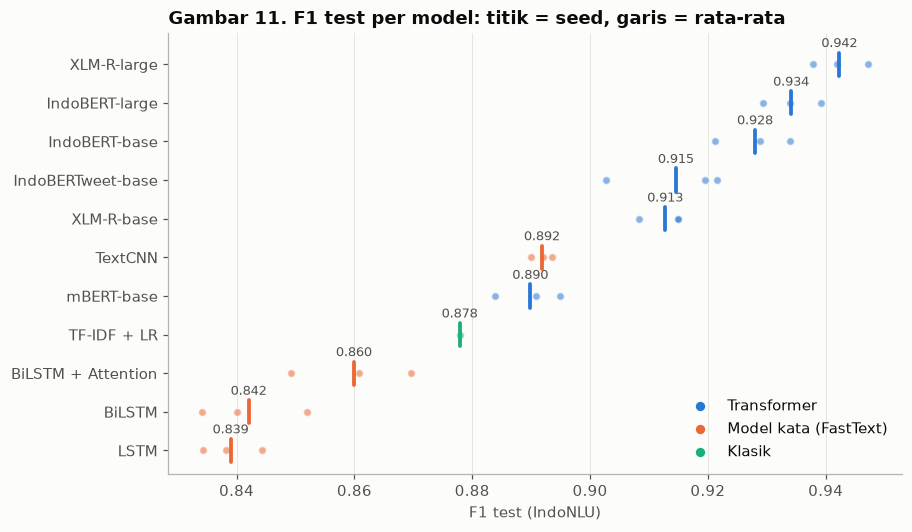

In [15]:
order = table.index[::-1]
fig, ax = plt.subplots(figsize=(8.6, 5.2))
for i, m in enumerate(order):
    r = runs[runs.model == m]
    c = FAMILY_COLOR[FAMILY[m]]
    ax.scatter(r.test_f1_indonlu, [i] * len(r), s=26, color=c, alpha=0.55, zorder=3, edgecolor=SURFACE, linewidth=1)
    mean = r.test_f1_indonlu.mean()
    ax.plot([mean, mean], [i - 0.3, i + 0.3], color=c, lw=2.5, solid_capstyle="round", zorder=4)
    ax.text(mean, i + 0.36, f"{mean:.3f}", ha="center", va="bottom", fontsize=8.5, color=INK_2)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("F1 test (IndoNLU)")
ax.set_ylim(-0.6, len(order) - 0.2)
ax.set_title("Gambar 11. F1 test per model: titik = seed, garis = rata-rata")
for fam, c in FAMILY_COLOR.items():
    ax.scatter([], [], color=c, s=26, label={"transformer": "Transformer", "kata": "Model kata (FastText)", "klasik": "Klasik"}[fam])
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "11_hasil_model.png")
plt.show()

Model terbaik adalah XLM-R-large dengan F1 test 0,942. Di antara model kata, LSTM (0,839) dan BiLSTM (0,842) hampir sama karena ulasan yang pendek tidak banyak terbantu oleh pembacaan dua arah. Attention menaikkan F1 menjadi 0,860, karena setiap aspek memerlukan kata yang berbeda. TextCNN (0,892) mengungguli semua RNN, karena sentimen aspek umumnya ditentukan oleh frasa pendek seperti "ac tidak dingin". TF-IDF + LR (0,878) juga mengalahkan ketiga RNN; dengan 2.260 ulasan latih, model berparameter jutaan belum tentu lebih baik daripada model linear.

Transformer unggul dengan selisih besar. Pada ukuran base, IndoBERT-base (0,928) lebih tinggi daripada IndoBERTweet (0,915), XLM-R-base (0,913), dan mBERT (0,890), sesuai dengan analisis tokenizer di notebook 1 bagian 7.7 (IndoBERT memecah kata paling sedikit). Pada ukuran large, XLM-R-large (0,942) melampaui IndoBERT-large (0,934). Exact match tertinggi adalah 0,788, sehingga sekitar satu dari lima ulasan masih memiliki aspek yang salah.

### 4.1 Uji signifikansi rantai model

Test hanya berisi 286 ulasan, sehingga selisih kecil dapat muncul karena pemilihan ulasan semata. Setiap pasangan yang berurutan dalam rantai diuji dengan bootstrap berpasangan (Efron & Tibshirani, 1993). Ulasan test diambil ulang dengan pengembalian sebanyak 2.000 kali, lalu selisih F1 kedua model dihitung pada setiap sampel. Prediksi setiap model berasal dari rata-rata probabilitas tiga seed, dan pasangan yang diuji ditetapkan sebelum hasil dilihat.

Selisih dianggap sebagai temuan apabila interval kepercayaan 95%-nya tidak memuat nol. Karena ada delapan perbandingan, ambang p dikoreksi dengan Bonferroni menjadi 0,05 / 8 = 0,00625.

In [16]:
from hoasa.metrics import f1_indonlu

SEEDS_OF = runs.groupby("model").seed.apply(list).to_dict()


def probs(name, split):
    return np.mean([np.load(ROOT / "outputs" / "preds" / f"{slug(name)}_s{s}.npz")[split] for s in SEEDS_OF[name]], 0)


BOOT = np.random.default_rng(0).integers(0, len(Y["test"]), (2000, len(Y["test"])))


def paired_bootstrap(a, b):
    pa, pb, y = probs(a, "test").argmax(-1), probs(b, "test").argmax(-1), Y["test"]
    d = np.array([f1_indonlu(y[i], pb[i]) - f1_indonlu(y[i], pa[i]) for i in BOOT])
    dv = f1_indonlu(Y["valid"], probs(b, "valid").argmax(-1)) - f1_indonlu(Y["valid"], probs(a, "valid").argmax(-1))
    return {"Δ valid": 100 * dv, "Δ test": 100 * (f1_indonlu(y, pb) - f1_indonlu(y, pa)),
            "CI 95% bawah": 100 * np.percentile(d, 2.5), "CI 95% atas": 100 * np.percentile(d, 97.5), "p (Δ ≤ 0)": (d <= 0).mean()}


CHAIN = [("TF-IDF + LR", "TextCNN", "deep learning non-transformer vs klasik"), ("BiLSTM", "BiLSTM + Attention", "attention"),
         ("BiLSTM + Attention", "TextCNN", "pola lokal (CNN) vs urutan (RNN)"), ("TextCNN", "IndoBERT-base", "pretraining Transformer"),
         ("XLM-R-base", "IndoBERT-base", "monolingual vs multibahasa (base)"), ("IndoBERT-base", "IndoBERT-large", "kapasitas, monolingual"),
         ("XLM-R-base", "XLM-R-large", "kapasitas, multibahasa"), ("IndoBERT-large", "XLM-R-large", "monolingual vs multibahasa (large)")]
boot = pd.DataFrame([{"pasangan": f"{a} → {b}", "gagasan": g, **paired_bootstrap(a, b)} for a, b, g in CHAIN]).set_index("pasangan")
boot["keputusan"] = np.select([boot["p (Δ ≤ 0)"] < 0.05 / 8, boot["CI 95% bawah"] > 0], ["temuan (lolos Bonferroni)", "temuan lemah"],
                              "interval memuat nol")
boot.style.format({c: "{:+.2f}" for c in ["Δ valid", "Δ test", "CI 95% bawah", "CI 95% atas"]} | {"p (Δ ≤ 0)": "{:.3f}"})

,gagasan,Δ valid,Δ test,CI 95% bawah,CI 95% atas,p (Δ ≤ 0),keputusan
pasangan,,,,,,,
TF-IDF + LR → TextCNN,deep learning non-transformer vs klasik,+3.19,+1.92,-0.24,+4.09,0.042,interval memuat nol
BiLSTM → BiLSTM + Attention,attention,+3.33,+1.87,-0.14,+4.25,0.035,interval memuat nol
BiLSTM + Attention → TextCNN,pola lokal (CNN) vs urutan (RNN),+0.95,+2.59,+0.29,+4.78,0.013,temuan lemah
TextCNN → IndoBERT-base,pretraining Transformer,+3.39,+3.30,+1.75,+5.04,0.000,temuan (lolos Bonferroni)
XLM-R-base → IndoBERT-base,monolingual vs multibahasa (base),+1.82,+0.79,-0.67,+2.39,0.163,interval memuat nol
IndoBERT-base → IndoBERT-large,"kapasitas, monolingual",+1.28,+0.04,-0.82,+0.91,0.467,interval memuat nol
XLM-R-base → XLM-R-large,"kapasitas, multibahasa",+3.56,+2.33,+0.71,+4.16,0.002,temuan (lolos Bonferroni)
IndoBERT-large → XLM-R-large,monolingual vs multibahasa (large),+0.46,+1.50,+0.28,+2.75,0.005,temuan (lolos Bonferroni)


Tiga selisih lolos koreksi Bonferroni, yaitu sumbangan pretraining (TextCNN ke IndoBERT-base, +3,30 poin), kapasitas pada model multibahasa (XLM-R-base ke XLM-R-large, +2,33 poin), dan keunggulan XLM-R-large atas IndoBERT-large (+1,50 poin). Keunggulan TextCNN atas BiLSTM + Attention (+2,59 poin) hanya signifikan sebelum koreksi, sehingga dicatat sebagai temuan lemah.

Attention dan TextCNN terhadap TF-IDF menaikkan F1 sekitar 3 poin di valid dan 2 poin di test, tetapi interval test keduanya masih memuat nol. Memperbesar IndoBERT tidak menghasilkan selisih yang terdeteksi di test (+0,04 poin), walaupun F1 valid naik 1,28 poin.

## 5. Perbandingan dengan Literatur

Angka pembanding diambil dari tabel hasil IndoNLU (Wilie dkk., 2020), yang memakai split, metrik, dan formulasi yang sama. Paper tersebut melaporkan satu angka per model tanpa simpangan baku.

In [17]:
PAPER = {"mBERT-base": 84.63, "XLM-R-base": 91.57, "IndoBERT-base": 92.07, "IndoBERT-large": 93.38, "XLM-R-large": 94.27}
lit = table.loc[list(PAPER), ["F1 test", "± sd"]].mul(100)
lit.insert(0, "paper (IndoNLU)", pd.Series(PAPER))
lit["selisih"] = lit["F1 test"] - lit["paper (IndoNLU)"]
lit.round(2)

,paper (IndoNLU),F1 test,± sd,selisih
mBERT-base,84.63,88.98,0.55,4.35
XLM-R-base,91.57,91.27,0.38,-0.30
IndoBERT-base,92.07,92.80,0.64,0.73
IndoBERT-large,93.38,93.41,0.49,0.03
XLM-R-large,94.27,94.23,0.47,-0.04


Hasil replikasi setara atau lebih tinggi daripada angka paper. IndoBERT-base lebih tinggi 0,73 poin, sedangkan XLM-R-base, IndoBERT-large, dan XLM-R-large berada dalam satu simpangan baku dari angka paper. mBERT lebih tinggi 4,35 poin. Paper IndoNLU memakai satu konfigurasi hiperparameter untuk semua model, dan konfigurasi tersebut kemungkinan kurang sesuai untuk mBERT.

Pembersihan data dan pelatihan empat kelas tidak menurunkan hasil, sehingga eksperimen selanjutnya tetap sebanding dengan literatur. IndoBERT-large yang dipakai adalah varian `-p2`; varian `-p1` memberikan hasil setara (notebook 3 bagian 5.5).

## 6. Dinamika Pelatihan

Gambar 12 memperlihatkan F1 valid per epoch untuk setiap seed. Titik menandai epoch terbaik yang dipakai untuk melaporkan F1 test.

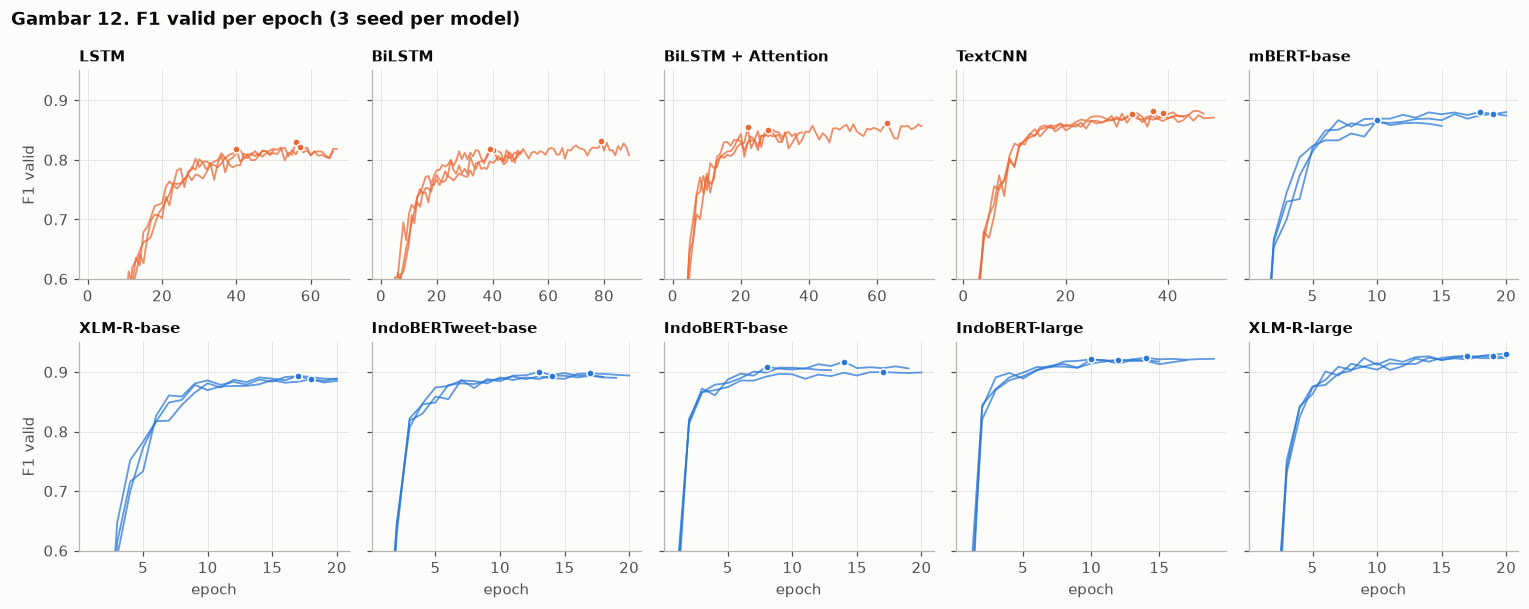

In [18]:
neural = [m for m in MODELS if FAMILY[m] != "klasik"]
fig, axes = plt.subplots(2, 5, figsize=(14, 5.6), sharey=True)
for ax, m in zip(axes.ravel(), neural):
    c = FAMILY_COLOR[FAMILY[m]]
    for _, r in runs[runs.model == m].iterrows():
        h = pd.DataFrame(r.history)
        ax.plot(h.epoch, h.valid_f1, color=c, lw=1.2, alpha=0.75)
        b = h.loc[h.valid_f1.idxmax()]
        ax.scatter(b.epoch, b.valid_f1, color=c, s=22, zorder=3, edgecolor=SURFACE, linewidth=1)
    ax.set_title(m, fontsize=10)
    ax.set_ylim(0.6, 0.95)
for ax in axes[1]:
    ax.set_xlabel("epoch")
for ax in axes[:, 0]:
    ax.set_ylabel("F1 valid")
fig.suptitle("Gambar 12. F1 valid per epoch (3 seed per model)", x=0.01, ha="left", fontweight="bold", fontsize=11.5)
fig.tight_layout()
fig.savefig(FIG_DIR / "12_kurva_pelatihan.png")
plt.show()

Model kata memerlukan puluhan epoch (rata-rata epoch terbaik 36–53) karena seluruh pengetahuan bahasanya dipelajari dari 2.260 ulasan. F1 valid LSTM dan BiLSTM mendatar di sekitar 0,82, BiLSTM + Attention di sekitar 0,85, dan TextCNN di sekitar 0,87, sehingga menambah epoch tidak akan menaikkannya.

Transformer melewati F1 valid 0,85 jauh lebih cepat, yaitu sekitar 3 epoch untuk IndoBERT, 5–6 epoch untuk IndoBERTweet dan XLM-R-large, serta 7–10 epoch untuk mBERT dan XLM-R-base. Variasi antar seed juga lebih kecil karena semua seed berangkat dari bobot pretrained yang sama. XLM-R-large mencapai epoch terbaik paling akhir (rata-rata 18,7 dari maksimum 20) dan mungkin masih dapat meningkat, tetapi batas 20 epoch dipertahankan agar protokolnya sama.

## 7. Biaya dan Performa

Gambar 13 membandingkan jumlah parameter setiap model dengan F1 test-nya.

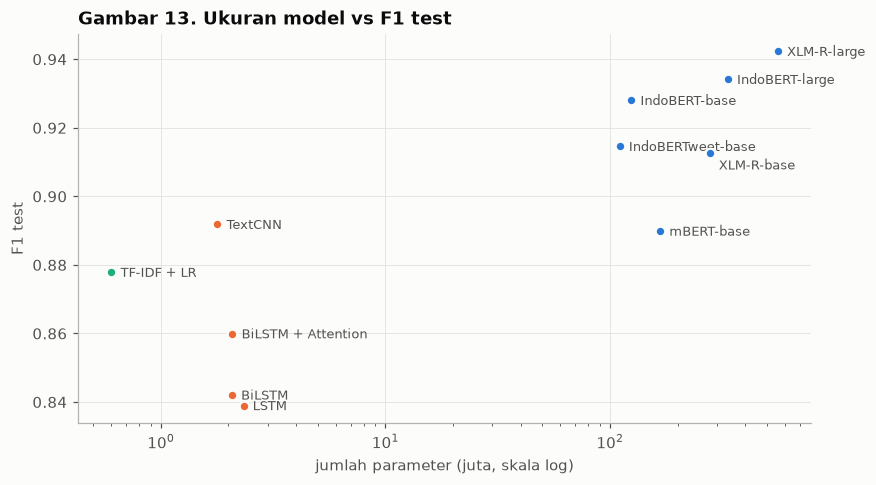

In [19]:
fig, ax = plt.subplots(figsize=(8.6, 4.6))
for m, r in table.iterrows():
    c = FAMILY_COLOR[r.keluarga]
    ax.scatter(r["parameter (juta)"], r["F1 test"], s=40, color=c, zorder=3, edgecolor=SURFACE, linewidth=1.5)
    dy = -11 if m == "XLM-R-base" else -3
    ax.annotate(m, (r["parameter (juta)"], r["F1 test"]), textcoords="offset points", xytext=(6, dy), fontsize=8.5, color=INK_2)
ax.set_xscale("log")
ax.set_xlabel("jumlah parameter (juta, skala log)")
ax.set_ylabel("F1 test")
ax.set_title("Gambar 13. Ukuran model vs F1 test")
fig.savefig(FIG_DIR / "13_biaya_performa.png")
plt.show()

Model klasik dan model kata berukuran 0,6–2,3 juta parameter dan dilatih dalam kurang dari satu menit per run, sedangkan transformer berukuran 110–560 juta parameter. Kenaikan terbesar per parameter terjadi dari model kata ke transformer base. Dari base ke large, F1 naik 0,6 poin untuk IndoBERT dan 3,0 poin untuk XLM-R, sementara waktu pelatihan naik dari 2,6 menit per run (IndoBERT-base) menjadi 6,4 menit (IndoBERT-large) dan 10,3 menit (XLM-R-large). Untuk sumber daya terbatas, IndoBERT-base merupakan kompromi terbaik, sedangkan XLM-R-large dipilih apabila akurasi tertinggi yang diutamakan.

## 8. Diagnostik: Penanganan `neg_pos` saat Pelatihan

Pada putaran pertama, `neg_pos` dipetakan menjadi `neg` sebelum pelatihan. Hasil IndoBERT-base saat itu sekitar 1,5 poin lebih rendah daripada eksperimen sebelumnya, dengan selisih yang terpusat pada kelas `pos`. Dugaan penyebabnya adalah sembilan sel `neg_pos` yang memuat pujian dan kritik untuk aspek yang sama; mengubahnya menjadi `neg` mengajarkan bahwa kata pujian dapat bermakna negatif. Bagian ini membandingkan versi tersebut dengan pelatihan empat kelas. Hasil versi tiga kelas disimpan di `outputs/results_3kelas.jsonl`, dan hanya model yang lengkap tiga seed pada kedua versi yang ditampilkan.

In [20]:
r3 = load_results(ROOT / "outputs" / "results_3kelas.jsonl")
both = [m for m in MODELS if (r3.model == m).sum() == (runs.model == m).sum() == 3]
diag = pd.DataFrame({
    "valid 3 kelas": r3.groupby("model").valid_f1_indonlu.mean(), "valid 4 kelas + gabung": runs.groupby("model").valid_f1_indonlu.mean(),
    "test 3 kelas": r3.groupby("model").test_f1_indonlu.mean(), "test 4 kelas + gabung": runs.groupby("model").test_f1_indonlu.mean(),
}).loc[both]
diag["Δ valid (poin)"] = 100 * (diag["valid 4 kelas + gabung"] - diag["valid 3 kelas"])
diag["Δ test (poin)"] = 100 * (diag["test 4 kelas + gabung"] - diag["test 3 kelas"])
display(diag.round(4))
print(f"Rata-rata Δ valid {diag['Δ valid (poin)'].mean():+.2f} poin, Δ test {diag['Δ test (poin)'].mean():+.2f} poin; "
      f"model dengan Δ valid > 0: {(diag['Δ valid (poin)'] > 0).sum()}/{len(diag)}")

,valid 3 kelas,valid 4 kelas + gabung,test 3 kelas,test 4 kelas + gabung,Δ valid (poin),Δ test (poin)
model,,,,,,
LSTM,0.8262,0.8234,0.8361,0.8390,-0.2824,0.2874
BiLSTM,0.8157,0.8220,0.8359,0.8420,0.6293,0.6117
BiLSTM + Attention,0.8515,0.8550,0.8611,0.8599,0.3504,-0.1208
TextCNN,0.8833,0.8792,0.8954,0.8918,-0.4147,-0.3598
IndoBERT-base,0.9014,0.9087,0.9174,0.9280,0.7271,1.0620


Rata-rata Δ valid +0.20 poin, Δ test +0.30 poin; model dengan Δ valid > 0: 3/5


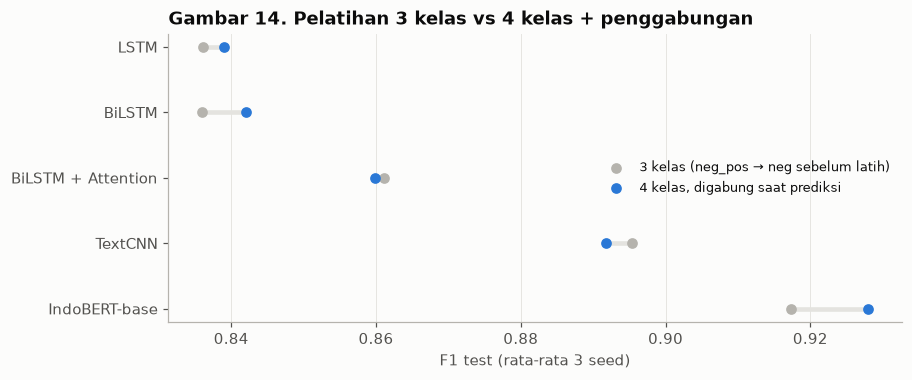

In [21]:
fig, ax = plt.subplots(figsize=(8.6, 3.4))
for i, m in enumerate(both[::-1]):
    a, b = diag.loc[m, "test 3 kelas"], diag.loc[m, "test 4 kelas + gabung"]
    ax.plot([a, b], [i, i], color=GRID, lw=3, zorder=1)
    ax.scatter(a, i, color=MUTED, s=36, zorder=3, label="3 kelas (neg_pos → neg sebelum latih)" if i == 0 else None)
    ax.scatter(b, i, color=FAMILY_COLOR["transformer"], s=36, zorder=3, label="4 kelas, digabung saat prediksi" if i == 0 else None)
ax.set_yticks(range(len(both)), both[::-1])
ax.set_xlabel("F1 test (rata-rata 3 seed)")
ax.set_title("Gambar 14. Pelatihan 3 kelas vs 4 kelas + penggabungan")
ax.legend(loc="center right", fontsize=8.5)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "14_diagnostik_negpos.png")
plt.show()

Efek terbesar terjadi pada IndoBERT-base, yaitu +0,73 poin di valid dan +1,06 poin di test. Pada model kata, perbedaannya di bawah 0,7 poin dengan arah yang tidak konsisten. Karena pelatihan empat kelas tidak pernah menurunkan F1 lebih dari 0,5 poin dan membantu transformer, semua hasil di notebook ini memakai cara tersebut. Keterbatasannya, bukti untuk transformer baru berasal dari satu model. Diagnostik ini juga dilakukan setelah hasil test putaran pertama terlihat, tetapi keputusannya didukung oleh selisih pada valid.

## 9. Kesimpulan

Model terbaik adalah XLM-R-large dengan F1 test 0,942 ± 0,005, setara dengan angka terbaik pada paper IndoNLU (94,27). Pada ukuran base, IndoBERT-base (0,928) merupakan pilihan terbaik dan paling efisien.

Uji bootstrap menunjukkan bahwa pretraining Transformer memberi lompatan terbesar (+3,3 poin dari TextCNN ke IndoBERT-base). Kapasitas tambahan membantu XLM-R (+2,3 poin) tetapi tidak IndoBERT (+0,04 poin). Attention dan TextCNN memberi kenaikan yang konsisten, tetapi belum signifikan pada test berukuran 286 ulasan. Hasil ini sejalan dengan EDA. Opini yang umumnya lokal membuat TextCNN unggul atas RNN, sedangkan aspek implisit memerlukan model kontekstual yang telah di-*pretrain*.

Exact match tertinggi masih sekitar 0,79. Notebook 3 menganalisis letak dan penyebab kesalahan model, kemudian menguji beberapa cara perbaikan, termasuk pendekatan baru berupa attention per aspek dengan query dari deskripsi aspek.